In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Iris dataset from GitHub
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)
df.head()



,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Bootstrap 95% CI for mean petal length: (3.48, 4.03)


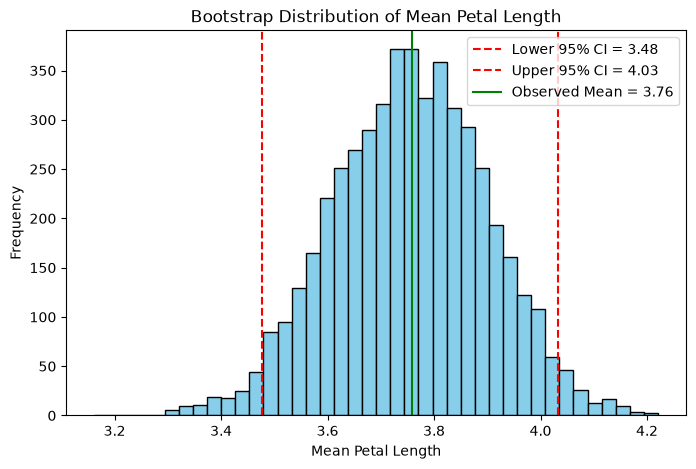

In [2]:
# Define groups correctly
setosa = df[df['species']=='setosa']['petal_length'].values
versicolor = df[df['species']=='versicolor']['petal_length'].values


# Bootstrap resampling
n_boot = 5000
boot_means = []
for _ in range(n_boot):
    sample = np.random.choice(df['petal_length'], size=len(df['petal_length']), replace=True)
    boot_means.append(np.mean(sample))

# 95% CI
ci_lower, ci_upper = np.percentile(boot_means, [2.5, 97.5])
print(f"Bootstrap 95% CI for mean petal length: ({ci_lower:.2f}, {ci_upper:.2f})")

# Visualization
plt.figure(figsize=(8,5))
plt.hist(boot_means, bins=40, color="skyblue", edgecolor="black")
plt.axvline(ci_lower, color="red", linestyle="--", label=f"Lower 95% CI = {ci_lower:.2f}")
plt.axvline(ci_upper, color="red", linestyle="--", label=f"Upper 95% CI = {ci_upper:.2f}")
plt.axvline(np.mean(df['petal_length']), color="green", linestyle="-", label=f"Observed Mean = {np.mean(df['petal_length']):.2f}")
plt.title("Bootstrap Distribution of Mean Petal Length")
plt.xlabel("Mean Petal Length")
plt.ylabel("Frequency")
plt.legend()
plt.show()  




In [3]:
import numpy as np
from scipy.stats import norm

# Generate synthetic data ~ Normal(μ=50, σ=10)
np.random.seed(42)
data = np.random.normal(loc=50, scale=10, size=100)

# MLE estimates
mu_mle = np.mean(data)
sigma2_mle = np.mean((data - mu_mle)**2)

print(f"MLE Mean (μ): {mu_mle:.2f}")
print(f"MLE Variance (σ²): {sigma2_mle:.2f}")


MLE Mean (μ): 48.96
MLE Variance (σ²): 81.65


MLE provides parameter estimates that maximize the likelihood of the observed data.

In your case, the estimates are close to the true values (𝜇=50,𝜎2=100), confirming that MLE is a reliable method.

With more data, the estimates would get even closer to the true parameters.